In [1]:
import os
from dotenv import load_dotenv

load_dotenv()

os.environ['GROQ_API_KEY']=os.getenv("GROQ_API_KEY")

from langchain_groq import ChatGroq
llm=ChatGroq(model='openai/gpt-oss-120b')

In [2]:
from langgraph.graph import StateGraph,START,END
from typing import Annotated
from langgraph.graph.message import add_messages
from typing_extensions import TypedDict
from langgraph.checkpoint.memory import MemorySaver
from langchain_core.tools import tool
from langgraph.prebuilt import ToolNode,tools_condition

In [3]:
class State(TypedDict):
    messages:Annotated[list,add_messages]
    topic:str
    joke:str
    explaination:str

In [4]:
from langchain_core.prompts import ChatPromptTemplate

joke_prompt = ChatPromptTemplate.from_template(
    "Generate a joke on the topic: {topic}"
)

explain_prompt = ChatPromptTemplate.from_template(
    "Explain this joke about {topic}: {joke}"
)

In [5]:
graph_builder=StateGraph(State)

#node1
def generate_joke(state:State):
    """this will generate the jokes based on the give topic"""
    res=(joke_prompt|llm).invoke({"topic":state['topic']})
    return {
        "joke": res.content,
        "messages": [res]
    }

#node2
def explain_joke(state:State):
    """this will explain the joke"""
    res=(explain_prompt | llm).invoke({
        "topic": state["topic"],
        "joke": state["joke"]
    })

    return {
        "explaination": res.content,
        "messages": [res]
    }

graph_builder.add_node("generate_joke",generate_joke)
graph_builder.add_node("explain_joke",explain_joke)

graph_builder.add_edge(START,"generate_joke")
graph_builder.add_edge("generate_joke","explain_joke")
graph_builder.add_edge("explain_joke",END)

memory=MemorySaver()

app = graph_builder.compile(checkpointer=memory)

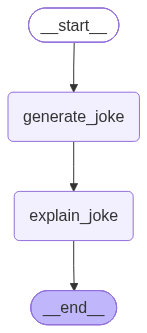

In [6]:

from IPython.display import Image, display

display(Image(app.get_graph().draw_mermaid_png()))

In [7]:
config1={"configurable":{"thread_id":"chat1"}}
result1 = app.invoke({
    "topic": "AI",
    "joke": "",
    "explaination": "",
    "messages": []
},config=config1)

print(result1['messages'])

[AIMessage(content='Why did the AI go to therapy?\n\nBecause it kept over‑thinking its *neural* networks and kept saying, “I’m not sure if I’m a model or a mess!”', additional_kwargs={'reasoning_content': "We need to generate a joke about AI. The user just wants a joke. There's no policy issue. Provide a joke. Probably short, witty."}, response_metadata={'token_usage': {'completion_tokens': 78, 'prompt_tokens': 79, 'total_tokens': 157, 'completion_time': 0.172045435, 'completion_tokens_details': {'reasoning_tokens': 31}, 'prompt_time': 0.003100117, 'prompt_tokens_details': None, 'queue_time': 0.31008328, 'total_time': 0.175145552}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_5082008e34', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a12a81-7ed2-7400-afe7-0a9f358437cc-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 79, 'output_tokens': 78, 'total_tokens': 157, 'output_token_de

In [8]:
for chunk in result1['messages']:
    print(chunk)

content='Why did the AI go to therapy?\n\nBecause it kept over‑thinking its *neural* networks and kept saying, “I’m not sure if I’m a model or a mess!”' additional_kwargs={'reasoning_content': "We need to generate a joke about AI. The user just wants a joke. There's no policy issue. Provide a joke. Probably short, witty."} response_metadata={'token_usage': {'completion_tokens': 78, 'prompt_tokens': 79, 'total_tokens': 157, 'completion_time': 0.172045435, 'completion_tokens_details': {'reasoning_tokens': 31}, 'prompt_time': 0.003100117, 'prompt_tokens_details': None, 'queue_time': 0.31008328, 'total_time': 0.175145552}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_5082008e34', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'} id='lc_run--01a12a81-7ed2-7400-afe7-0a9f358437cc-0' tool_calls=[] invalid_tool_calls=[] usage_metadata={'input_tokens': 79, 'output_tokens': 78, 'total_tokens': 157, 'output_token_details': {'reasoni

In [9]:
print("Joke:", result1["joke"])
print("Explanation:", result1["explaination"])

Joke: Why did the AI go to therapy?

Because it kept over‑thinking its *neural* networks and kept saying, “I’m not sure if I’m a model or a mess!”
Explanation: **The joke:**  
*Why did the AI go to therapy?*  
*Because it kept over‑thinking its **neural** networks and kept saying, “I’m not sure if I’m a model or a mess!”*

---

### 1. The set‑up → “Why did the AI go to therapy?”

- **Therapy** is something people (or, in jokes, anthropomorphized things) do when they’re stressed, anxious, or have “mental” issues.  
- By asking why an *AI* would need therapy, the joke immediately treats the machine as if it had human‑like feelings and insecurities.

### 2. The punchline → “Because it kept over‑thinking its *neural* networks …”

| Phrase | What it means in AI | What it hints at in the joke |
|--------|---------------------|------------------------------|
| **Neural networks** | A type of machine‑learning model inspired by the brain’s network of neurons. | “Neural” sounds like “neuro‑” (re

In [10]:
list(app.get_state_history(config1))

[StateSnapshot(values={'messages': [AIMessage(content='Why did the AI go to therapy?\n\nBecause it kept over‑thinking its *neural* networks and kept saying, “I’m not sure if I’m a model or a mess!”', additional_kwargs={'reasoning_content': "We need to generate a joke about AI. The user just wants a joke. There's no policy issue. Provide a joke. Probably short, witty."}, response_metadata={'token_usage': {'completion_tokens': 78, 'prompt_tokens': 79, 'total_tokens': 157, 'completion_time': 0.172045435, 'completion_tokens_details': {'reasoning_tokens': 31}, 'prompt_time': 0.003100117, 'prompt_tokens_details': None, 'queue_time': 0.31008328, 'total_time': 0.175145552}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_5082008e34', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a12a81-7ed2-7400-afe7-0a9f358437cc-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 79, 'output_tokens': 78, 't

In [11]:
app.get_state({"configurable":{"thread_id":"chat1",'checkpoint_id': '1f1c55e7-5dd4-6200-8000-834dffa4b480'}})

StateSnapshot(values={'messages': [], 'topic': 'AI', 'joke': '', 'explaination': ''}, next=('generate_joke',), config={'configurable': {'thread_id': 'chat1', 'checkpoint_id': '1f1c55e7-5dd4-6200-8000-834dffa4b480'}}, metadata={'source': 'loop', 'step': 0, 'parents': {}}, created_at='2026-10-11T10:28:12.022835+00:00', parent_config={'configurable': {'thread_id': 'chat1', 'checkpoint_ns': '', 'checkpoint_id': '1f1c55e7-5dbb-6b75-bfff-c99b471ecfbd'}}, tasks=(PregelTask(id='daa252ef-9d52-246b-1464-d0b6c417a65d', name='generate_joke', path=('__pregel_pull', 'generate_joke'), error=None, interrupts=(), state=None, result={'joke': 'Why did the AI go to therapy?\n\nBecause it kept over‑thinking its *neural* networks and kept saying, “I’m not sure if I’m a model or a mess!”', 'messages': [AIMessage(content='Why did the AI go to therapy?\n\nBecause it kept over‑thinking its *neural* networks and kept saying, “I’m not sure if I’m a model or a mess!”', additional_kwargs={'reasoning_content': "We n

In [12]:
app.invoke(None,{"configurable":{"thread_id":"chat1",'checkpoint_id': '1f1c55e7-5dd4-6200-8000-834dffa4b480'}})

{'messages': [AIMessage(content='Why did the AI go to therapy?  \n\nIt kept over‑thinking its **neural** networks and kept telling itself, “I’m not *artificial*—I’m just *deep*ly confused!”', additional_kwargs={'reasoning_content': 'The user wants a joke about AI. Provide a joke. Should be appropriate. Probably just one-liner.'}, response_metadata={'token_usage': {'completion_tokens': 75, 'prompt_tokens': 79, 'total_tokens': 154, 'completion_time': 0.157115882, 'completion_tokens_details': {'reasoning_tokens': 23}, 'prompt_time': 0.003077325, 'prompt_tokens_details': None, 'queue_time': 0.211638285, 'total_time': 0.160193207}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_a655021f7d', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a12a8b-10a1-7dc2-8374-5b070d4f0edb-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 79, 'output_tokens': 75, 'total_tokens': 154, 'output_token_details